# 01 - loadcast: what does the plant's demand look like?

[loadcast](https://github.com/Matt-haug/loadcast) makes synthetic hourly
heat, cold and electricity demand for an industrial site. It's not a
forecaster, it's a generator: you give it annual energy and a "process
class" and it gives back a year of hourly kW.

Things I want to find out here:
1. What does the base case look like?
2. How different are the four process classes?
3. Does `carrier_correlation` do what it says?
4. What does the random seed change?
5. Is the 1 MW heat pump from the plan big enough for this demand?

In [1]:
import sys
sys.path.insert(0, "..")

import loadcast
import matplotlib.pyplot as plt
import pandas as pd

import config

plt.rcParams["figure.dpi"] = 72   # keeps the notebook file small
print("loadcast", loadcast.__version__)
print("process classes:", loadcast.available_classes())

loadcast 1.0.4
process classes: ['batch', 'campaign', 'continuous', 'semi_continuous']


## 1. Base case

Settings come from `config.py`: 10 GWh/yr, 20% electricity, heat:cold of
7.4, semi-continuous (weekday shifts, weekend dip), correlation 0.75.

In [2]:
def make_demand(process_class=config.PROCESS_CLASS, correlation=config.CARRIER_CORRELATION, seed=42):
    return loadcast.generate(
        year=config.YEAR,
        annual_mwh=config.ANNUAL_MWH,
        heat_to_cold=config.HEAT_TO_COLD,
        elec_share=config.ELEC_SHARE,
        process_class=process_class,
        carrier_correlation=correlation,
        seed=seed,
    )

demand = make_demand()
demand.head()

,heat_kw,cold_kw,elec_kw,waste_kw
2025-01-01 00:00:00,865.274883,209.768942,436.522953,0.0
2025-01-01 01:00:00,651.086463,159.058761,426.379915,0.0
2025-01-01 02:00:00,837.227139,188.688121,516.924400,0.0
2025-01-01 03:00:00,980.995530,164.661348,353.787783,0.0
2025-01-01 04:00:00,877.654752,128.928125,311.703188,0.0


There's a `waste_kw` column too. It's all zeros unless you ask for waste
heat, so I'll drop it.

In [3]:
demand = demand[["heat_kw", "cold_kw", "elec_kw"]]
summary = pd.DataFrame({
    "annual_MWh": demand.sum() / 1000,
    "mean_kW": demand.mean(),
    "peak_kW": demand.max(),
    "min_kW": demand.min(),
})
summary.round(0)

,annual_MWh,mean_kW,peak_kW,min_kW
heat_kw,7048.0,805.0,2006.0,123.0
cold_kw,952.0,109.0,271.0,16.0
elec_kw,2000.0,228.0,569.0,39.0


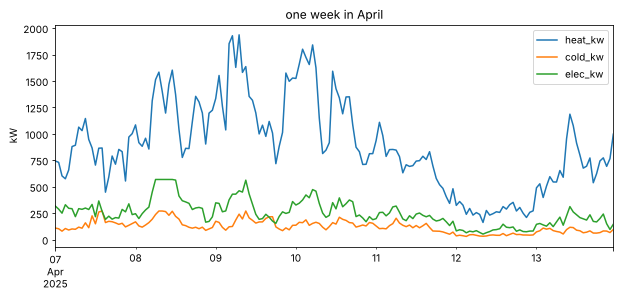

In [4]:
demand.loc[f"{config.YEAR}-04-07":f"{config.YEAR}-04-13"].plot(figsize=(10, 4), title="one week in April")
plt.ylabel("kW");

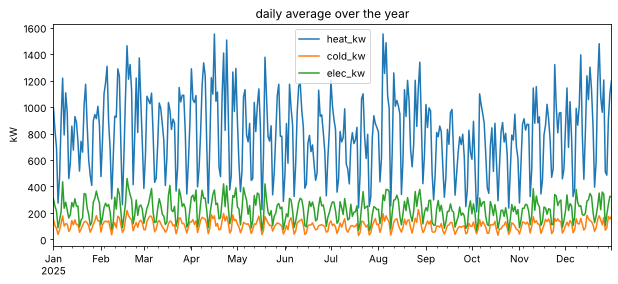

In [5]:
# whole year, daily averages, to see if there's any seasonality
demand.resample("D").mean().plot(figsize=(10, 4), title="daily average over the year")
plt.ylabel("kW");

Mostly flat over the year with weekly dips and some holidays. That makes
sense: loadcast doesn't model weather at all, so there's no "more heat in
winter". For process heat in a food plant that's roughly right.

## 2. The four process classes
Same annual energy, different class.

,class,heat_peak_kw,heat_load_factor,hours_below_10pct_of_peak
0,batch,3640.37,0.22,5301
1,campaign,1599.45,0.50,1717
2,continuous,1396.74,0.58,0
3,semi_continuous,2006.29,0.40,113


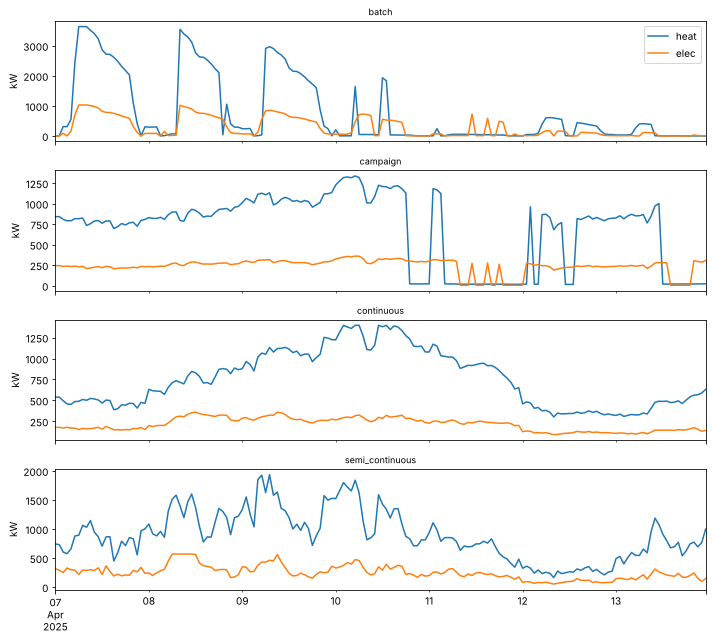

In [6]:
fig, axes = plt.subplots(4, 1, sharex=True, figsize=(10, 9))
rows = []
for ax, pc in zip(axes, loadcast.available_classes()):
    d = make_demand(process_class=pc)
    d.loc[f"{config.YEAR}-04-07":f"{config.YEAR}-04-13", ["heat_kw", "elec_kw"]].plot(ax=ax, legend=False)
    ax.set_title(pc, fontsize=9)
    ax.set_ylabel("kW")
    rows.append({
        "class": pc,
        "heat_peak_kw": d.heat_kw.max(),
        "heat_load_factor": d.heat_kw.mean() / d.heat_kw.max(),
        "hours_below_10pct_of_peak": (d.heat_kw < 0.1 * d.heat_kw.max()).sum(),
    })
axes[0].legend(["heat", "elec"], loc="upper right")
plt.tight_layout()
pd.DataFrame(rows).round(2)

Batch is wild: peak almost 2x semi-continuous, idle most of the year.
Storage would look amazing for batch. I'm staying with semi-continuous
for now as the middle ground.

## 3. Does `carrier_correlation` do what it says?
Ask for a correlation, then measure what we actually get.

In [7]:
import warnings

rows = []
for c in [0.0, 0.25, 0.5, 0.75, 0.95]:
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        d = make_demand(correlation=c)
    rows.append({
        "asked_for": c,
        "got_heat_vs_elec": d.heat_kw.corr(d.elec_kw),
        "got_heat_vs_cold": d.heat_kw.corr(d.cold_kw),
        "loadcast_warned": any(isinstance(x.message, loadcast.TargetMissedWarning) for x in w),
    })
pd.DataFrame(rows).round(2)

,asked_for,got_heat_vs_elec,got_heat_vs_cold,loadcast_warned
0,0.00,0.46,0.46,True
1,0.25,0.46,0.46,True
2,0.50,0.50,0.50,False
3,0.75,0.75,0.75,False
4,0.95,0.95,0.95,False


**Didn't work below ~0.46.** Above 0.5 it's spot on, but you can't get
lower than about 0.46: loadcast warns that all carriers share one shift
calendar, so they move together even when the random part is independent.
The fix it suggests is giving a carrier its own calendar
(`DemandSpec.calendars`). Note for later: a correlation sweep should
start at 0.5, not 0.

## 4. What does the seed change?

annual heat MWh: 7048 vs 7048
hourly correlation between the two seeds: 0.47


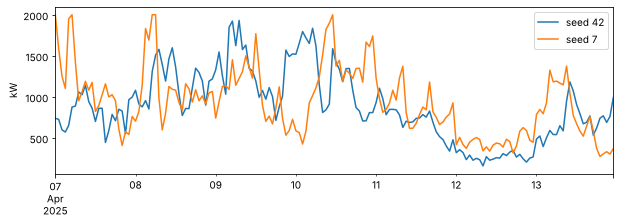

In [8]:
a = make_demand(seed=42)
b = make_demand(seed=7)
print("annual heat MWh:", round(a.heat_kw.sum() / 1000), "vs", round(b.heat_kw.sum() / 1000))
print("hourly correlation between the two seeds:", round(a.heat_kw.corr(b.heat_kw), 2))

ax = a.heat_kw.loc[f"{config.YEAR}-04-07":f"{config.YEAR}-04-13"].plot(figsize=(10, 3), label="seed 42")
b.heat_kw.loc[f"{config.YEAR}-04-07":f"{config.YEAR}-04-13"].plot(ax=ax, label="seed 7")
ax.legend(); ax.set_ylabel("kW");

Annual energy is identical (it rescales to hit the target), but the hours
only correlate ~0.47. So "same plant, different year" is quite different.
Useful later: train a forecaster on one seed and test on another.

## 5. Is a 1 MW heat pump enough?

average heat demand: 805 kW
peak heat demand:    2006 kW
hours above 1000 kW:  2366   (heat pump would run 80% of the time on average)
hours above 1500 kW:   449   (heat pump would run 54% of the time on average)
hours above 2000 kW:    63   (heat pump would run 40% of the time on average)


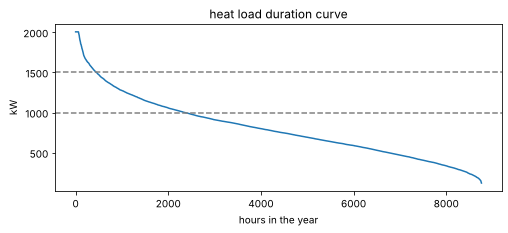

In [9]:
heat = demand.heat_kw
print(f"average heat demand: {heat.mean():.0f} kW")
print(f"peak heat demand:    {heat.max():.0f} kW")
for hp_kw in [1000, 1500, 2000]:
    print(f"hours above {hp_kw} kW: {(heat > hp_kw).sum():5d}   "
          f"(heat pump would run {heat.mean() / hp_kw:.0%} of the time on average)")

# load duration curve
ldc = heat.sort_values(ascending=False).reset_index(drop=True)
ax = ldc.plot(figsize=(8, 3), title="heat load duration curve")
for hp_kw in [1000, 1500]:
    ax.axhline(hp_kw, ls="--", color="grey")
ax.set_xlabel("hours in the year"); ax.set_ylabel("kW");

**Problem:** with an average of ~805 kW, a 1 MW heat pump would have to run
~80% of the year just to keep up, with nothing left to shift load to cheap
hours. And it's above 1 MW for a lot of hours. Options for the PyPSA
notebook: a bigger heat pump, or a backup gas boiler (most food plants
have one anyway).

## Save for the other notebooks

In [10]:
out = config.DATA_DIR / "demand_loadcast.csv"
demand.index.name = "time"
demand.to_csv(out)
print("saved", out)

saved /home/user/energy_dt_ml/notebooks/../data/demand_loadcast.csv
